# 02 · Seven routes to the same spectra

`MultiTrap` solves the linearised quantum Langevin equations of particles in a cavity by seven
routes that share as little code as possible - numerical inversion of the full drift problem,
hybridisation of the one-dimensional solutions, a factorial power series, and a closed form. This
notebook runs all seven on three systems, measures how closely they agree and how long each takes,
and ends with a guide to choosing one.

**Runtime:** about 10 s, most of it in the power series. **Background:**
[Calculation methods](../../docs/concepts/calculation_methods.md) (what each route computes, and
where in the code) and [Spectra of several particles in one cavity](../../docs/guide/cavity_spectra.md).

In [ ]:
import time

import numpy as np
import matplotlib.pyplot as plt

from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import kHz, degrees
from levisim.multiphysics.enums import QuantumLinearTheoryMethod
from levisim.multiphysics.multitrap import MultiTrap
from levisim.multiphysics.utils.shelf import (
    DEFAULT_cavity_kwargs,
    DEFAULT_gas_kwargs,
    OFF_NODE_toy_params_pairs,
    PHASE_DEPENDENT_toy_params,
)

set_plt_rcParams_to_xmgrace_style()
METHODS = list(QuantumLinearTheoryMethod)
LAM = QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
SHORT = {
    'LINEAR_AMPLIFIER_MODEL': '(1) LAM',
    'HYBRID_LINEAR_AMPLIFIER_MODEL': '(2) hybrid LAM',
    'TNT_LINEAR_AMPLIFIER_MODEL': '(3) TNT LAM',
    'NUMERICAL_HYBRIDISATION': '(4) numerical hybr.',
    'POWER_SERIES_HYBRIDISATION': '(5) power series',
    'ANALYTIC_INSIDE_CAVITY': '(6) analytic, inside',
    'ANALYTIC_CAVITY_OUTPUT': '(7) analytic, output',
}
print([method.name for method in METHODS])

['LINEAR_AMPLIFIER_MODEL', 'HYBRID_LINEAR_AMPLIFIER_MODEL', 'TNT_LINEAR_AMPLIFIER_MODEL', 'NUMERICAL_HYBRIDISATION', 'POWER_SERIES_HYBRIDISATION', 'ANALYTIC_INSIDE_CAVITY', 'ANALYTIC_CAVITY_OUTPUT']


## 1. Three test systems

Each has two particles moving in $x$ and $y$ (four dimensions, so the drift matrix is 10×10):

- **physical**: the system of [`01_quickstart_cavity_spectra`](01_quickstart_cavity_spectra.ipynb),
  built from tweezer, bead, gas and cavity parameters (tweezer phases 0° and 30°);
- **`PHASE_DEPENDENT` toy**: toy parameters from `levisim.multiphysics.utils.shelf`, with four
  different couplings and tweezer phases 0° and 30°;
- **`OFF_NODE` toy**: particles away from the cavity node, so each particle's $x$ and $y$ are also
  coupled directly ($g_{xy} \neq 0$) - the case the closed form (6), (7) only handles since it was
  generalised in the Nov 2026 analytic PR.

`load_in_power_series=True` loads the pre-generated derangement power series for method (5)
(`levisim/multiphysics/power_series_data/4D_2x2_up_to_4.pickle`, shipped with the package).

In [ ]:
common = dict(num_traps=2, Cartesian_axes_per_trap=2, gas_kwargs=DEFAULT_gas_kwargs,
              cavity_kwargs=DEFAULT_cavity_kwargs, load_in_power_series=True)
systems = {
    'physical': MultiTrap(ω_range=np.linspace(125, 165, 700) * kHz, φn_dict={2: 30 * degrees}, **common),
    'PHASE_DEPENDENT toy': MultiTrap(ω_range=np.linspace(285, 320, 700) * kHz,
                                     toy_params=PHASE_DEPENDENT_toy_params, **common),
    'OFF_NODE toy': MultiTrap(ω_range=np.linspace(285, 320, 700) * kHz,
                              toy_params=OFF_NODE_toy_params_pairs, **common),
}
for name, mtrap in systems.items():
    Ωs = ', '.join(f'{label} {dim.Ω / kHz:.1f}' for label, dim in mtrap.dimensions.items())
    print(f'{name:20s} Ω/2π (kHz): {Ωs}; g_xy/2π = {mtrap.dimensions["x1"].gxy / kHz:.2f} kHz')

physical             Ω/2π (kHz): x1 156.3, y1 135.8, x2 152.1, y2 137.6; g_xy/2π = -0.00 kHz
PHASE_DEPENDENT toy  Ω/2π (kHz): x1 305.0, y1 307.5, x2 298.0, y2 300.5; g_xy/2π = 0.00 kHz
OFF_NODE toy         Ω/2π (kHz): x1 305.0, y1 307.5, x2 298.0, y2 300.5; g_xy/2π = -2.00 kHz


2026-11-19 19:45:32.860 | WARNING  | levisim.multiphysics.multitrap.base:_check_linear_stability:357 - MultiTrap(2×2): 2 of the 10 drift-matrix eigenvalues have a positive real part (largest Re λ = +574 /s, an e-folding time of 1.74 ms, on the mode at |Im λ| = 301.04 kHz), so the linearised dynamics are unstable and have no steady state: the stationary spectra are formally finite but do not describe a physical steady state. Check the detuning Δ, the couplings and the tweezer phases φn.


## 2. Run every method

For each system and method, compute the homodyne spectrum and all four position PSDs, time them,
and record the largest relative difference from LAM over the grid. Method (3), TNT, builds the
matrix of all operator spectra $\mathbf T\mathbf N\mathbf T^\dagger$ without input-output theory, so it
has no optical spectra and raises `ValueError` for a homodyne spectrum.

In [ ]:
def run(function, *args):
    # call a levisim spectrum function; return (result, seconds)
    start = time.perf_counter()
    result = function(*args)
    return result, time.perf_counter() - start

TNT = QuantumLinearTheoryMethod.TNT_LINEAR_AMPLIFIER_MODEL
try:
    systems['physical'].homodyne_spectrum(TNT)
except ValueError as error:   # levisim also logs it as an ERROR
    print(f'{TNT.name} has no homodyne spectrum: ValueError: {error}')

results = {}   # (system, method name) -> dict
for name, mtrap in systems.items():
    num_points = len(mtrap.ω_range)
    for method in METHODS:
        entry = {'hom': None, 'hom_μs': np.nan}
        if method != TNT:
            entry['hom'], seconds = run(mtrap.homodyne_spectrum, method)
            entry['hom_μs'] = 1e6 * seconds / num_points
        (psd_array, _), seconds = run(mtrap.all_position_power_spectra, method)
        entry['psd'], entry['psd_μs'] = psd_array, 1e6 * seconds / num_points
        results[name, method.name] = entry

def max_rel_diff(a, b):
    return np.max(np.abs(a / b - 1))

for name in systems:
    print(f'\n{name}: largest relative difference from LAM, and cost per frequency point')
    print(f'{"method":24s} {"homodyne":>10s} {"PSDs":>10s} {"hom. μs":>9s} {"PSDs μs":>9s}')
    ref = results[name, LAM.name]
    for method in METHODS:
        entry = results[name, method.name]
        d_hom = '-' if entry['hom'] is None else f'{max_rel_diff(entry["hom"], ref["hom"]):.1e}'
        print(f'{SHORT[method.name]:24s} {d_hom:>10s} {max_rel_diff(entry["psd"], ref["psd"]):10.1e}'
              f' {entry["hom_μs"]:9.0f} {entry["psd_μs"]:9.0f}')

TNT_LINEAR_AMPLIFIER_MODEL has no homodyne spectrum: ValueError: TNT LAM only gives position power spectra: use all_position_power_spectra, or another method for the homodyne spectrum

physical: largest relative difference from LAM, and cost per frequency point
method                     homodyne       PSDs   hom. μs   PSDs μs
(1) LAM                     0.0e+00    0.0e+00        34        79
(2) hybrid LAM              2.8e-15    0.0e+00        51        74
(3) TNT LAM                       -    1.0e-15       nan        16
(4) numerical hybr.         6.7e-15    1.2e-14       226       175
(5) power series            8.4e-15    8.2e-15      1896      1700
(6) analytic, inside        6.2e-15    8.0e-15       117       228
(7) analytic, output        6.8e-15    8.0e-15       115       222

PHASE_DEPENDENT toy: largest relative difference from LAM, and cost per frequency point
method                     homodyne       PSDs   hom. μs   PSDs μs
(1) LAM                     0.0e+00    0.0e+00

2026-11-19 19:45:32.867 | ERROR    | levisim.multiphysics.multitrap.base:_log_spectrum_call:1141 - TNT LAM only gives position power spectra: use all_position_power_spectra, or another method for the homodyne spectrum


Every route agrees with LAM to better than $10^{-13}$ on every system, including unequal
tweezer phases and direct $x$-$y$ coupling. That is the main evidence that each is right: the
routes share the drift matrix and the noise model, but not the algebra that turns them into a
spectrum.

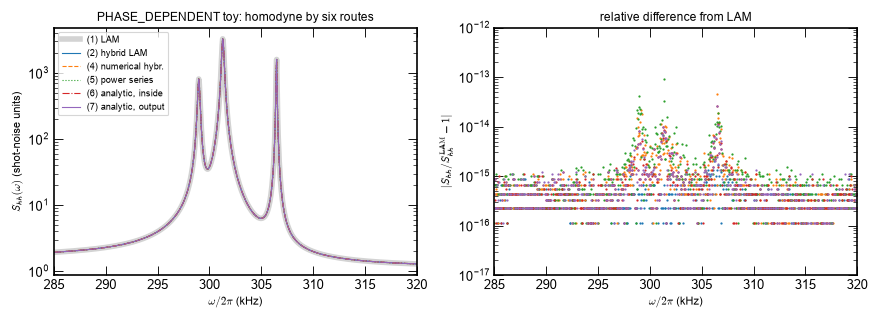

In [ ]:
name = 'PHASE_DEPENDENT toy'
mtrap = systems[name]
f = mtrap.ω_range / kHz
ref = results[name, LAM.name]['hom']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.semilogy(f, ref, color='lightgrey', lw=5, label='(1) LAM')
styles = ['-', '--', ':', '-.']
for ii, method in enumerate(m for m in METHODS if m != LAM and results[name, m.name]['hom'] is not None):
    ax1.semilogy(f, results[name, method.name]['hom'], ls=styles[ii % 4], lw=1, label=SHORT[method.name])
    ax2.semilogy(f, np.abs(results[name, method.name]['hom'] / ref - 1), '.', ms=2, label=SHORT[method.name])
for ax in (ax1, ax2):
    ax.set_xlim(f[0], f[-1])
    ax.set_xlabel(r'$\omega / 2\pi$ (kHz)')
ax1.set_ylabel(r'$S_{hh}(\omega)$ (shot-noise units)')
ax2.set_ylabel(r'$|S_{hh} / S_{hh}^\mathrm{LAM} - 1|$')
ax2.set_ylim(1e-17, 1e-12)
ax1.legend(fontsize=8, loc='upper left')
ax1.set_title(f'{name}: homodyne by six routes', fontsize=11)
ax2.set_title('relative difference from LAM', fontsize=11)
fig.tight_layout()

The differences sit at the level of double-precision rounding ($10^{-16}$ to $10^{-15}$; exact
zeros are off the bottom of the log scale) away from the peaks and grow towards $10^{-14}$ on them, where each route divides by small quantities in a
different order.

## 3. Cross spectra

The single-position functions have cross-spectrum counterparts. Compare the complex
$S_{q_{x_1} q_{x_2}}(\omega)$ from four routes, including the TNT array of all position cross spectra:

In [ ]:
mtrap = systems['PHASE_DEPENDENT toy']
csd = {}
for method in [LAM, QuantumLinearTheoryMethod.NUMERICAL_HYBRIDISATION, QuantumLinearTheoryMethod.ANALYTIC_CAVITY_OUTPUT]:
    csd[SHORT[method.name]], _ = run(mtrap.position_cross_spectrum, 'x1', 'x2', method)
i, j = mtrap.label_to_index['x1'], mtrap.label_to_index['x2']
array, _ = run(lambda: mtrap.position_cross_spectra_array)
csd['(3) TNT LAM'] = array[:, i, j]
for label, values in csd.items():
    print(f'{label:24s} max |S/S_LAM - 1| = {np.max(np.abs(values / csd["(1) LAM"] - 1)):.1e}')

(1) LAM                  max |S/S_LAM - 1| = 1.2e-16
(4) numerical hybr.      max |S/S_LAM - 1| = 4.6e-14
(7) analytic, output     max |S/S_LAM - 1| = 2.9e-14
(3) TNT LAM              max |S/S_LAM - 1| = 3.6e-15


## 4. Agreement is not stability

The `OFF_NODE` system has a normal mode with negative damping (a positive real part of a
drift-matrix eigenvalue), so it has no steady state - levisim logged a WARNING when it was built,
in section 1. The seven routes agree on it anyway, because they all evaluate the same
frequency-domain response, and a Lorentzian does not depend on the sign of its width. Agreement
between routes checks the algebra; checking that a steady state exists is a separate step:

In [ ]:
for name, mtrap in systems.items():
    growth = np.max(np.linalg.eigvals(mtrap.drift_matrix).real)
    print(f'{name:20s} largest Re λ = {growth:+9.1f} /s -> {"stable" if growth < 0 else "UNSTABLE"}')

physical             largest Re λ =    -294.0 /s -> stable
PHASE_DEPENDENT toy  largest Re λ =    -264.8 /s -> stable
OFF_NODE toy         largest Re λ =    +574.0 /s -> UNSTABLE


## 5. Which method to use

Cost per frequency point for the four-dimensional systems above, averaged over the three systems:

(1) LAM                  homodyne      36 μs   PSDs      54 μs
(2) hybrid LAM           homodyne      45 μs   PSDs      72 μs
(3) TNT LAM              homodyne     nan μs   PSDs      40 μs
(4) numerical hybr.      homodyne     194 μs   PSDs     163 μs
(5) power series         homodyne    1736 μs   PSDs    1653 μs
(6) analytic, inside     homodyne     112 μs   PSDs     272 μs
(7) analytic, output     homodyne     111 μs   PSDs     260 μs


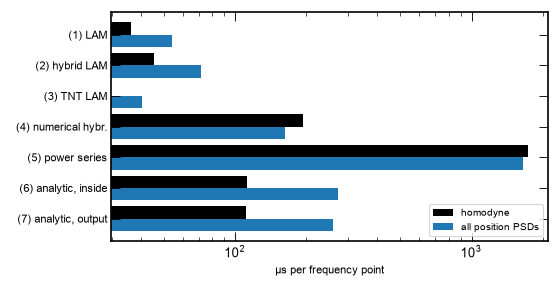

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.6))
names = [SHORT[m.name] for m in METHODS]
hom_μs = [np.mean([results[s, m.name]['hom_μs'] for s in systems]) for m in METHODS]   # nan for TNT
psd_μs = [np.mean([results[s, m.name]['psd_μs'] for s in systems]) for m in METHODS]
y = np.arange(len(METHODS))
ax.barh(y - 0.2, hom_μs, height=0.4, color='k', label='homodyne')
ax.barh(y + 0.2, psd_μs, height=0.4, color='tab:blue', label='all position PSDs')
ax.set_yticks(y, names, fontsize=10)
ax.invert_yaxis()
ax.set_xscale('log')
ax.set_xlabel('μs per frequency point')
ax.legend(fontsize=9, loc='lower right')
fig.tight_layout()
for n, h, p in zip(names, hom_μs, psd_μs):
    print(f'{n:24s} homodyne {h:7.0f} μs   PSDs {p:7.0f} μs')

Absolute timings depend on the machine; the ordering is what matters. At this size:

| task | use | why |
|---|---|---|
| any spectrum, by default | (1) LAM | the reference: one $(2N+2)$-square inverse per frequency |
| every position PSD at once | (3) TNT LAM | fastest; one $\mathbf T\mathbf N\mathbf T^\dagger$ per frequency, positions only |
| an independent check of the light | (2) hybrid LAM | rebuilds the light from the mechanics through $\chi_\text{c}(\omega)$ and $\chi_\text{c}^*(-\omega)$ |
| which motions hybridise, and how strongly | (4) numerical hybridisation | exposes the hybridisation functions $R_{j_n k_m}(\omega)$; checked against the Fortran reference |
| the hybridisation order by order | (5) power series | sums of derangement cycles; cost grows factorially, see [`05_derangements_and_hybridisation`](05_derangements_and_hybridisation.ipynb) |
| insight, and large systems | (6), (7) closed form | collective sums over the dimensions, no $N\times N$ inverse |

The per-point costs here are dominated by Python overhead; how they scale with the number of
particles is in the showcase notebook,
[`showcase/many_particles_one_cavity`](../showcase/many_particles_one_cavity.ipynb).